In [2]:
import pandas as pd
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, confusion_matrix

print("Loading Train and Test sets...")
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

target = 'target'
features = [
    'loan_amnt', 'term', 'emp_length', 'home_ownership', 'annual_inc',
    'verification_status', 'purpose', 'dti', 'delinq_2yrs', 'fico_range_low',
    'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc'
]

X_train = train_df[features].copy()
y_train = train_df[target]
X_test = test_df[features].copy()
y_test = test_df[target]

numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# XGBoost uses a specific parameter to balance classes instead of 'class_weight'
# scale_pos_weight = (count of negative examples) / (count of positive examples)
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

model_xgb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb.XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric='auc',
        max_depth=4,            # Keep trees shallow to prevent overfitting
        learning_rate=0.1,
        n_estimators=100
    ))
])

print("Training XGBoost (Model B)...")
model_xgb.fit(X_train, y_train)

y_pred_proba_xgb = model_xgb.predict_proba(X_test)[:, 1]
y_pred_xgb = model_xgb.predict(X_test)

auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)

print("\n--- XGBoost Performance (Test Set) ---")
print(f"XGBoost ROC-AUC: {auc_xgb:.4f} (Target to beat: 0.6584)")

print("\n--- XGBoost Confusion Matrix (Threshold = 0.5) ---")
cm = confusion_matrix(y_test, y_pred_xgb)
print(f"True Negatives (Good predicted Good): {cm[0][0]}")
print(f"False Positives (Good predicted Bad):  {cm[0][1]} (Lost revenue)")
print(f"False Negatives (Bad predicted Good):  {cm[1][0]} (Financial loss)")
print(f"True Positives (Bad predicted Bad):   {cm[1][1]} (Risk avoided)")

# Save probabilities for the business layer (Phase 6)
test_df['lr_prob'] = y_test # Placeholder, we will rely on XGBoost
test_df['xgb_prob'] = y_pred_proba_xgb
test_df.to_csv('test_with_probs.csv', index=False)

Loading Train and Test sets...
Training XGBoost (Model B)...

--- XGBoost Performance (Test Set) ---
XGBoost ROC-AUC: 0.6616 (Target to beat: 0.6584)

--- XGBoost Confusion Matrix (Threshold = 0.5) ---
True Negatives (Good predicted Good): 52396
False Positives (Good predicted Bad):  35909 (Lost revenue)
False Negatives (Bad predicted Good):  5566 (Financial loss)
True Positives (Bad predicted Bad):   9810 (Risk avoided)


Loading test predictions...
Total Loans Evaluated: 103,681
Strategy 1 (Approve All) Profit: $6,044,751.96
Strategy 2 (Grade A-D) Profit:   $10,226,499.01
Strategy 3 (XGBoost) Profit:     $21,924,837.64 (at 0.50 threshold)

Value added by XGBoost vs Grade Rule: $11,698,338.63


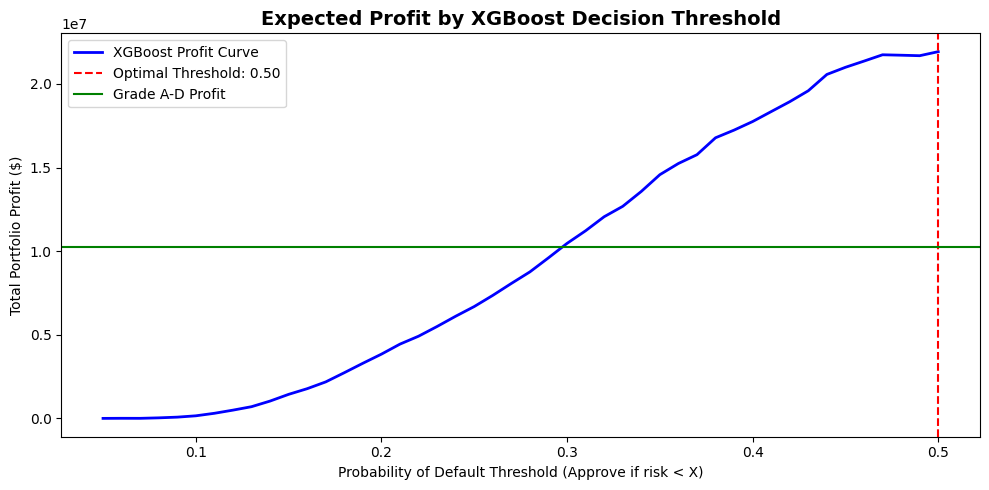

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Loading test predictions...")
df_biz = pd.read_csv('test_with_probs.csv')

# Business Assumptions
LGD = 0.60  # Loss Given Default: We lose 60% of the principal on a default

# Calculate raw financial impact for every single loan IF it were approved
df_biz['realized_profit'] = np.where(
    df_biz['target'] == 0,
    df_biz['loan_amnt'] * (df_biz['int_rate'] / 100),
    -df_biz['loan_amnt'] * LGD
)

print(f"Total Loans Evaluated: {len(df_biz):,}")

# Strategy 1: Approve Everyone
profit_all = df_biz['realized_profit'].sum()
print(f"Strategy 1 (Approve All) Profit: ${profit_all:,.2f}")

# Strategy 2: Grade-Based Rule (Approve Grades A, B, C, D)
approved_grade = df_biz[df_biz['grade'].isin(['A', 'B', 'C', 'D'])]
profit_grade = approved_grade['realized_profit'].sum()
print(f"Strategy 2 (Grade A-D) Profit:   ${profit_grade:,.2f}")

# Strategy 3: XGBoost Model Optimization
thresholds = np.arange(0.05, 0.51, 0.01)
profits_xgb = []

for t in thresholds:
    approved_xgb = df_biz[df_biz['xgb_prob'] < t]
    profits_xgb.append(approved_xgb['realized_profit'].sum())

max_profit_xgb = max(profits_xgb)
best_threshold = thresholds[profits_xgb.index(max_profit_xgb)]

print(f"Strategy 3 (XGBoost) Profit:     ${max_profit_xgb:,.2f} (at {best_threshold:.2f} threshold)")
print(f"\nValue added by XGBoost vs Grade Rule: ${max_profit_xgb - profit_grade:,.2f}")

# Plot the Profit Curve
plt.figure(figsize=(10, 5))
plt.plot(thresholds, profits_xgb, label='XGBoost Profit Curve', color='blue', linewidth=2)
plt.axvline(x=best_threshold, color='red', linestyle='--', label=f'Optimal Threshold: {best_threshold:.2f}')
plt.axhline(y=profit_grade, color='green', linestyle='-', label='Grade A-D Profit')
plt.title('Expected Profit by XGBoost Decision Threshold', fontsize=14, fontweight='bold')
plt.xlabel('Probability of Default Threshold (Approve if risk < X)')
plt.ylabel('Total Portfolio Profit ($)')
plt.legend()
plt.tight_layout()
plt.show()